In [78]:
import numpy as np
import matplotlib.pyplot as plt

def plot_voxel_by_index(skel, flat_idx, cmap='gray'):
    """
    Visualize a voxel in a 3D skeleton array by its flattened index.

    Parameters
    ----------
    skel : np.ndarray
        3D array (e.g., skeleton volume).
    flat_idx : int
        Flattened index from np.flatnonzero(skel).
    cmap : str, optional
        Colormap for display (default 'gray').
    """
    # Get (y, x, z) coordinates from flat index
    y, x, z = np.unravel_index(flat_idx, skel.shape)

    # Show the correct slice
    plt.imshow(skel[:, :, z], cmap=cmap, origin='upper')

    # Highlight voxel
    plt.scatter(x, y, color='red', s=10, marker='s', label=f'Flat idx {flat_idx}')
    plt.colorbar()
    plt.title(f'z = {z}  |  voxel = ({y}, {x}, {z})')
    plt.show()

def BinarizeImage(Im:np.ndarray, frangi_sigma = 8, frangi_enabled = True, method = "Fuzzy Means") -> np.ndarray:
    """
    Binarizes an image using the selected method and options from the GUI app.

    Parameters:
    - app: GUI application object containing UI state (e.g., checkboxes, dropdowns)
    - Im: Input image as a 2D NumPy array (grayscale)

    Returns:
    - Binarized image as a 2D NumPy array (dtype=float)
    """
    # Find the brightest pixel in the image
    col_max_vals = np.max(Im, axis=0) # the maximum of each column
    cc = np.argmax(col_max_vals) #  gets the index of the column where the brightest value occurred
    rr = np.argmax(Im[:, cc]) # captures the row index of that max value

    #	•	rr: row of the brightest pixel
	#   •	cc: column of the brightest pixel
    #   •	So (rr, cc) is the coordinate of the brightest pixel in the whole image.

    # Apply Frangi filter if selected
    if frangi_enabled:
        opts = {
            'sigmarange': [1, frangi_sigma],
            'sigmastepsize': 2,
            'correctionconst1': 0.8,
            'correctionconst2': 15
        }
        Im = frangi_2Dfilter(Im, opts)

    # Apply the selected binarization method
    if method == 'Fuzzy Means':
        nth = 2
        Im = fuzzy_thresholding(Im, nth, 3) - 1

    elif method == 'Adaptive Thresholding':
        Im = adaptive_thresholding(Im, 70).astype(float)

    else:
        raise ValueError("Incorrect Segmentation Method")

    # Ensure vessels are white, background is black, turning the image into black and white
    vessel_value = Im[rr, cc]
    Im[Im == vessel_value] = 255
    Im[Im != 255] = 0

    return Im

def overlay_mask(img, mask, color=(1, 0, 0), alpha=0.5):
    """
    Overlay a binary mask on a grayscale image.

    Parameters:
    - img: grayscale image (H,W)
    - mask: binary mask (H,W), values 0 or 255
    - color: tuple with RGB values (0-1 range for matplotlib)
    - alpha: transparency of overlay

    Returns:
    - RGB image with overlay
    """
    # Normalize grayscale for display
    img_norm = cv.normalize(img, None, 0, 1, cv.NORM_MINMAX)

    # Convert grayscale to RGB
    img_rgb = np.stack([img_norm]*3, axis=-1)

    # Create color mask
    mask_bool = mask > 0
    overlay = np.zeros_like(img_rgb)
    overlay[mask_bool] = color

    # Blend images
    blended = (1 - alpha) * img_rgb + alpha * overlay
    return blended


def center_crop(img, dim):
    """
    Center crop an image (2D NumPy array).

    Parameters:
        img (np.ndarray): Input image (H x W).
        dim (tuple): Desired output size (h, w).

    Returns:
        np.ndarray: Cropped image of size (h, w).
    """
    h, w = img.shape[:2]
    new_h, new_w = dim

    if new_h > h or new_w > w:
        raise ValueError("Crop size must be smaller than the image size")

    top = (h - new_h) // 2
    left = (w - new_w) // 2

    return img[top: top + new_h, left: left + new_w]


In [79]:
from skimage.io import imread
from skimage.filters import frangi
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize, remove_small_objects
from scipy.ndimage import distance_transform_edt
from Skel2Graph3D import skel2graph3d

import sys
sys.path.append("../../")
from frangi_2dfilter import frangi_2Dfilter
from fuzzy_thresholding import fuzzy_thresholding
from adaptive_thresholding import adaptive_thresholding

octa = imread("../../../assets/MIPs/10301.bmp")

# Frangi vessel enhancement
vessels = frangi(
    octa,
    scale_range=(0.5, 4),
    scale_step=0.5,
    alpha=0.5,
    beta=0.5,
    gamma=4,
    black_ridges=False
)

adpt_mask = BinarizeImage(vessels, frangi_sigma=8, frangi_enabled=False,
                            method="Adaptive Thresholding")

adpt_mask_cropped = center_crop(adpt_mask, dim=(50, 50)).astype(np.uint16)
skel = skeletonize(adpt_mask_cropped).astype(np.uint)
skel_padded = skel[:, :, np.newaxis]
skel_padded = np.pad(skel_padded, pad_width=1, mode='constant')

node, link = skel2graph3d(adpt_mask_cropped, 0)

/var/folders/j8/24ft1_090l56tpp7kwbz30gm0000gn/T/ipykernel_15334/1521611095.py:17: UserWarning: Use keyword parameter `sigmas` instead of `scale_range` and `scale_range` which will be removed in version 0.17.
  vessels = frangi(


In [80]:
len(node)

79

In [81]:
len(link)

16

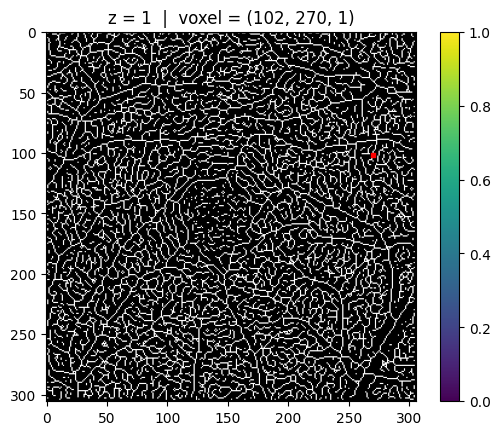

In [ ]:
plot_voxel_by_index(skel_padded, 94447)

# Figuring out how to translate lin idx from 3D to 2D

In [84]:
# --- your unpadding helper ---
def unpad_indices(indices, padded_shape):
    unpadded_shape = (padded_shape[0] - 2, padded_shape[1] - 2, padded_shape[2] - 2)
    x, y, z = np.unravel_index(indices, padded_shape) # get all x, y, z coordinates of all linear indices that are wrt 3D skel
    x, y, z = x - 1, y - 1, z - 1
    valid = (
        (x >= 0) & (x < unpadded_shape[0]) &
        (y >= 0) & (y < unpadded_shape[1]) &
        (z >= 0) & (z < unpadded_shape[2])
    )

    # check if any of the linear indices that are wrt to the 3D space are for some reason 
    # out of bound for when moved to the 2D space (they shouldn't because 3D is just padding, no info should be lost!)
    if not np.all(valid):
        invalid_coords = np.column_stack([x[~valid], y[~valid], z[~valid]])
        raise ValueError(
            f"Some coordinates are out of bounds after unpadding:\n"
            f"{invalid_coords[:10]}...\n"
            f"Unpadded shape: {unpadded_shape}\n"
            f"Total invalid: {np.sum(~valid)}"
        )

    x, y, z = x[valid], y[valid], z[valid]
    return np.ravel_multi_index((x, y, z), unpadded_shape)

# --- define small padded skeleton ---
# Original 2D skeleton (unpadded)
orig = np.zeros((3, 3), dtype=bool)
orig[1, 1] = True

# Add z dimension and pad as in skel2graph3d
skel = orig[:, :, np.newaxis]
skel = np.pad(skel, pad_width=1, mode="constant")

# Check shape
print("Original shape:", orig.shape)
print("Padded shape:", skel.shape)

# --- pick an example index ---
# The voxel that corresponds to the original [1,1,0] (in unpadded coords)
unpadded_idx = np.ravel_multi_index((1, 1, 0), orig.shape + (1,))
print("Unpadded index:", unpadded_idx)

# Now compute its index in the padded image (after +1 shift)
padded_idx = np.ravel_multi_index((1+1, 1+1, 0+1), skel.shape)
print("Padded index:", padded_idx)

# --- unpad back using your function ---
mapped_back = unpad_indices(np.array([padded_idx]), skel.shape)
print("Mapped back:", mapped_back)

# --- verify consistency ---
assert mapped_back[0] == unpadded_idx
print("✅ Mapping is consistent!")


Original shape: (3, 3)
Padded shape: (5, 5, 3)
Unpadded index: 4
Padded index: 37
Mapped back: [4]
✅ Mapping is consistent!


In [85]:
import numpy as np
import matplotlib.pyplot as plt

def plot_voxel_index_mapping(skel3D, skel2D, flat_idx, cmap='gray'):
    """
    Visualize how a 3D voxel index maps to the corresponding 2D skeleton.

    Parameters
    ----------
    skel3D : np.ndarray
        3D skeleton (e.g., padded volume).
    skel2D : np.ndarray
        2D skeleton (unpadded version, typically shape (H, W) or (H, W, 1)).
    flat_idx : int
        Linear index (e.g., from np.flatnonzero(skel3D)).
    cmap : str, optional
        Colormap for display (default 'gray').
    """
    # --- Get 3D coordinates from the flat index ---
    y, x, z = np.unravel_index(flat_idx, skel3D.shape)

    # --- Sanity check ---
    if z >= skel2D.shape[-1]:
        raise ValueError(f"Voxel z={z} is out of bounds for 2D skeleton with shape {skel2D.shape}")

    # --- Extract the corresponding slices ---
    slice3D = skel3D[:, :, z]
    slice2D = skel2D[:, :, 0] if skel2D.ndim == 3 else skel2D

    # --- Plot both side-by-side ---
    fig, axs = plt.subplots(1, 2, figsize=(8, 4))

    axs[0].imshow(slice3D, cmap=cmap, origin='upper')
    axs[0].scatter(x, y, color='red', s=20, marker='s')
    axs[0].set_title(f"3D skel slice (z={z})\nFlat idx={flat_idx}, voxel=({y},{x},{z})")

    axs[1].imshow(slice2D, cmap=cmap, origin='upper')
    axs[1].scatter(x, y, color='blue', s=20, marker='s')
    axs[1].set_title("2D skel (unpadded)")

    for ax in axs:
        ax.axis('off')

    plt.tight_layout()
    plt.show()


In [86]:
print(node[2])

node_cluster(
  nodes_idx: [ 259  262  271  274  415  418  421  424  427  577  580  583  736  739
  742  895  898 1057 1186 1189 1192 1213 1216 1342 1345 1348 1351 1369
 1372 1501 1504 1507 1510 1513 1516 1519 1531 1534 1669 1672 1675 1687
 1690 1828 1831 1834 1843 1846 1987 1990 1993 1999 2002 2146 2149 2152
 2155 2158 2296 2302 2305 2308 2311 2314 2317 2320 2323 2452 2455 2464
 2467 2470 2473 2476 2479 2482 2485 2488 2638 2641 2644 2647 2776 2779
 2800 2803 2932 2935 2959 3088 3091 3115 3241 3244 3247 3268 3271 3397
 3400 3403 3424 3427 3553 3556 3559 3577 3580 3583 3712 3715 3730 3733
 3736 3868 3871 3883 3886 3889 4024 4027 4030 4039 4042 4183 4186 4189
 4192 4195 4342 4345 4348 4351 4498 4501 4504 4516 4519 4654 4657 4660
 4669 4672 4675 4807 4810 4813 4822 4825 4960 4963 4966 4969 4975 4978
 4981 5116 5119 5122 5128 5131 5134 5137 5272 5275 5278 5290 5293 5425
 5428 5431 5449 5452 5578 5581 5584 5587 5590 5605 5608 5734 5737 5740
 5743 5746 5764 5767 5887 5890 5893 5902 5905 5923

In [ ]:
ex_indices = node[2].nodes_idx

In [87]:
x, y, z = np.unravel_index(259, skel_padded.shape) # padded dimensions (3D skel)
print(x, y, z)
x, y, z = x - 1, y - 1, z - 1
np.ravel_multi_index((x, y, z), skel.shape) # unpadded dimensions (2D skel)

1 34 1


ValueError: invalid entry in coordinates array

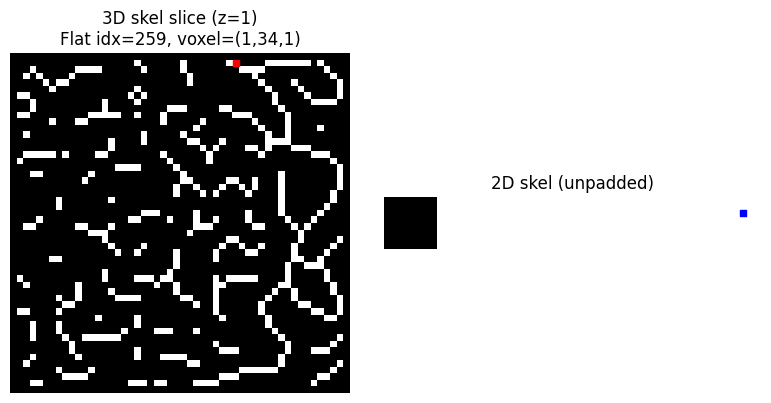

In [88]:
plot_voxel_index_mapping(skel_padded, skel, 259)

In [ ]:
y, x, z = np.unravel_index(2374, skel_padded.shape)